In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
import joblib 
import os

# Variáveis de configuração
id_novo_cliente = 'Cliente_Alvo_70'
ativos_novo_cliente = [('1832421D CN', 1436.22), ('1SANPN', 1436.22), ('2458693D US',1436.22), ('IGSN14 CDIE', 10000)]
classificacao_do_forms = 'Sofisticado/Arrojado' 

# Definição de caminhos para os arquivos
base_path_data = '../data/'
path_barema = os.path.join(base_path_data, 'processed/barema_por_ativo.csv')
path_class_tipos = os.path.join(base_path_data, 'raw/classificacao_de_tipos.csv')
path_subgrupo_dist = os.path.join(base_path_data, 'processed/subgrupo_distribuicao.csv')
path_user_item = os.path.join(base_path_data, 'processed/user_item_binario.csv')

# Inicialização das variáveis globais
TODOS_SUBGRUPOS_KMEANS = None

# Carregamento dos dados
try:
    df_barema = pd.read_csv(path_barema)
    df_class_tipos = pd.read_csv(path_class_tipos)
    df_subgrupo_dist_historico = pd.read_csv(path_subgrupo_dist)
    df_user_item_historico = pd.read_csv(path_user_item)
    print("Arquivos CSV carregados com sucesso!")
except FileNotFoundError as e:
    print(f"Erro ao carregar arquivo: {e}. Verifique os caminhos.")
    raise

if 'CONTA' in df_subgrupo_dist_historico.columns:
    df_subgrupo_dist_historico.set_index('CONTA', inplace=True)
    # Definir TODOS_SUBGRUPOS_KMEANS após carregar o dataframe
    TODOS_SUBGRUPOS_KMEANS = [col for col in df_subgrupo_dist_historico.columns if col != 'ClusterKMeans']
else:
    print("AVISO: Coluna 'CONTA' não encontrada em df_subgrupo_dist_historico.")

conta_col_user_item = None
if 'CONTA' in df_user_item_historico.columns:
    conta_col_user_item = 'CONTA'
elif 'Conta' in df_user_item_historico.columns:
    df_user_item_historico.rename(columns={'Conta':'CONTA'}, inplace=True)
    conta_col_user_item = 'CONTA'

if conta_col_user_item:
    df_user_item_historico.set_index(conta_col_user_item, inplace=True)
    TODOS_ATIVOS_HISTORICOS = df_user_item_historico.columns.tolist()
else:
    print("AVISO: Coluna 'CONTA'/'Conta' não encontrada em df_user_item_historico.")
    TODOS_ATIVOS_HISTORICOS = []


if 'NomeAtivo' not in df_barema.columns and 'NOME ATIVO' in df_barema.columns:
    df_barema.rename(columns={'NOME ATIVO': 'NomeAtivo'}, inplace=True)
if 'ClassificacaoDoAtivo' not in df_barema.columns and 'CLASSIFICACAO DO ATIVO' in df_barema.columns:
    df_barema.rename(columns={'CLASSIFICACAO DO ATIVO': 'ClassificacaoDoAtivo'}, inplace=True)


print(f"Barema: {df_barema.shape}")
print(f"Classificação Tipos: {df_class_tipos.shape}")
print(f"Subgrupo Dist Histórico: {df_subgrupo_dist_historico.shape}")
print(f"User Item Histórico: {df_user_item_historico.shape}")
df_barema.head(2)

Arquivos CSV carregados com sucesso!
Barema: (8046, 3)
Classificação Tipos: (81, 3)
Subgrupo Dist Histórico: (6101, 14)
User Item Histórico: (6102, 8046)
Barema: (8046, 3)
Classificação Tipos: (81, 3)
Subgrupo Dist Histórico: (6101, 14)
User Item Histórico: (6102, 8046)


,NomeAtivo,ClassificacaoDoAtivo,Subgrupo
0,1832421D CN,Renda Variável,RV - Ações Internacionais e ADRs
1,1SANPN,Renda Variável,RV - Ações Nacionais


In [2]:
print(f"--- Processando Cliente Alvo: {id_novo_cliente} ---")
ativos_cliente_alvo_dict = {item[0]: item[1] for item in ativos_novo_cliente}
df_carteira_alvo_rf_rv = pd.DataFrame(ativos_novo_cliente, columns=['NomeAtivo', 'VALOR INVESTIDO'])

df_carteira_alvo_rf_rv = pd.merge(
    df_carteira_alvo_rf_rv,
    df_barema[['NomeAtivo', 'ClassificacaoDoAtivo']],
    on='NomeAtivo',
    how='left'
)

ativos_nao_encontrados_rf_rv = df_carteira_alvo_rf_rv[df_carteira_alvo_rf_rv['ClassificacaoDoAtivo'].isnull()]
if not ativos_nao_encontrados_rf_rv.empty:
    print("\nAVISO (RF/RV): Os seguintes ativos do cliente alvo não foram encontrados no 'barema_por_ativo.csv' ou não possuem 'ClassificacaoDoAtivo':")
    print(ativos_nao_encontrados_rf_rv[['NomeAtivo', 'VALOR INVESTIDO']])
    df_carteira_alvo_rf_rv.dropna(subset=['ClassificacaoDoAtivo'], inplace=True)


dist_financeira_alvo = df_carteira_alvo_rf_rv.groupby('ClassificacaoDoAtivo')['VALOR INVESTIDO'].sum()
total_investido_alvo = dist_financeira_alvo.sum()
percentual_financeiro_alvo = pd.Series(dtype='float64')
perfil_calculado_alvo = "Moderado" 
type_to_buy = None 
ajuste_mensagem = f"Perfil Declarado: {classificacao_do_forms}."


if total_investido_alvo > 0:
    percentual_financeiro_alvo = (dist_financeira_alvo / total_investido_alvo * 100).fillna(0)
    rf_pct_alvo = percentual_financeiro_alvo.get('Renda Fixa', 0.0)
    rv_pct_alvo = percentual_financeiro_alvo.get('Renda Variável', 0.0)

    if rf_pct_alvo >= 90.0:
        perfil_calculado_alvo = "Conservador"
    elif rv_pct_alvo >= 70.0:
        perfil_calculado_alvo = "Sofisticado"
    else:
        perfil_calculado_alvo = "Moderado"
    
    print(f"\nDistribuição Financeira RF/RV do Cliente Alvo '{id_novo_cliente}':")
    print(percentual_financeiro_alvo)
    print(f"Perfil Calculado (baseado em RF/RV): {perfil_calculado_alvo}")

    ajuste_mensagem = f"Perfil Calculado: {perfil_calculado_alvo}. Perfil Declarado: {classificacao_do_forms}."

    if perfil_calculado_alvo != classificacao_do_forms:
        ajuste_mensagem += " Recomenda-se ajuste."
        if classificacao_do_forms == "Conservador":
            if rf_pct_alvo < 90.0: type_to_buy = "Renda Fixa"
        elif classificacao_do_forms == "Sofisticado": 
            if rv_pct_alvo < 70.0: type_to_buy = "Renda Variável"
        elif classificacao_do_forms == "Moderado":
            if rf_pct_alvo >= 90.0: 
                type_to_buy = "Renda Variável"
            elif rv_pct_alvo >= 70.0: 
                type_to_buy = "Renda Fixa"
else:
    perfil_calculado_alvo = "Indefinido (sem ativos válidos ou valor total 0 para cálculo RF/RV)"
    ajuste_mensagem = f"Não foi possível calcular o perfil RF/RV (carteira vazia ou ativos não reconhecidos no barema). Perfil Declarado: {classificacao_do_forms}."

print(f"\n{ajuste_mensagem}")
if type_to_buy:
    print(f"Tipo de ativo sugerido para ajuste: {type_to_buy}")


print("\n--- Calculando Distribuição de Subgrupos do Cliente Alvo (Simplificado) ---")
df_carteira_alvo_para_subgrupos = pd.DataFrame(ativos_novo_cliente, columns=['NomeAtivo', 'VALOR INVESTIDO'])

df_carteira_alvo_subgrupos_final = pd.merge(
    df_carteira_alvo_para_subgrupos,
    df_barema[['NomeAtivo', 'Subgrupo']],
    on='NomeAtivo',
    how='left'
)

ativos_sem_subgrupo_barema = df_carteira_alvo_subgrupos_final[df_carteira_alvo_subgrupos_final['Subgrupo'].isnull()]
if not ativos_sem_subgrupo_barema.empty:
    print("\nAVISO (Subgrupo): Os seguintes ativos do cliente alvo não foram encontrados no 'barema_por_ativo.csv' ou não possuem 'Subgrupo' definido lá:")
    print(ativos_sem_subgrupo_barema[['NomeAtivo', 'VALOR INVESTIDO']])
    df_carteira_alvo_subgrupos_final.dropna(subset=['Subgrupo'], inplace=True)

if df_carteira_alvo_subgrupos_final.empty:
    print("Nenhum ativo do cliente alvo pôde ser mapeado para um subgrupo a partir do 'barema_por_ativo.csv'. O vetor para K-Means será de zeros.")
    subgrupo_dist_alvo_pct = pd.Series(dtype='float64')
else:
    subgrupo_dist_alvo_valores = df_carteira_alvo_subgrupos_final.groupby('Subgrupo')['VALOR INVESTIDO'].sum()
    total_investido_alvo_subgrupos = subgrupo_dist_alvo_valores.sum()
    subgrupo_dist_alvo_pct = pd.Series(dtype='float64')

    if total_investido_alvo_subgrupos > 0:
        subgrupo_dist_alvo_pct = (subgrupo_dist_alvo_valores / total_investido_alvo_subgrupos * 100).fillna(0)

# Verificar e atualizar TODOS_SUBGRUPOS_KMEANS se necessário
if TODOS_SUBGRUPOS_KMEANS is None:
    if df_subgrupo_dist_historico is not None and not df_subgrupo_dist_historico.empty:
        TODOS_SUBGRUPOS_KMEANS = [col for col in df_subgrupo_dist_historico.columns if col != 'ClusterKMeans']
        print(f"TODOS_SUBGRUPOS_KMEANS definido com {len(TODOS_SUBGRUPOS_KMEANS)} subgrupos")
    else:
        print("ERRO CRÍTICO: Não foi possível definir TODOS_SUBGRUPOS_KMEANS pois df_subgrupo_dist_historico não está disponível")
        raise ValueError("TODOS_SUBGRUPOS_KMEANS não pode ser definido")

vetor_cliente_alvo_para_kmeans = pd.Series(0.0, index=TODOS_SUBGRUPOS_KMEANS)
for subgrupo, pct in subgrupo_dist_alvo_pct.items():
    if subgrupo in vetor_cliente_alvo_para_kmeans.index:
        vetor_cliente_alvo_para_kmeans[subgrupo] = pct
    else:
        print(f"AVISO: Subgrupo '{subgrupo}' (calculado para o cliente alvo) não está na lista de TODOS_SUBGRUPOS_KMEANS. Será ignorado para K-Means.")

print("\nDistribuição de Subgrupos do Cliente Alvo (para K-Means - SIMPLIFICADO):")
print(vetor_cliente_alvo_para_kmeans[vetor_cliente_alvo_para_kmeans > 0])

--- Processando Cliente Alvo: Cliente_Alvo_70 ---

Distribuição Financeira RF/RV do Cliente Alvo 'Cliente_Alvo_70':
ClassificacaoDoAtivo
Renda Fixa        69.887746
Renda Variável    30.112254
Name: VALOR INVESTIDO, dtype: float64
Perfil Calculado (baseado em RF/RV): Moderado

Perfil Calculado: Moderado. Perfil Declarado: Sofisticado/Arrojado. Recomenda-se ajuste.

--- Calculando Distribuição de Subgrupos do Cliente Alvo (Simplificado) ---

Distribuição de Subgrupos do Cliente Alvo (para K-Means - SIMPLIFICADO):
RF - Títulos Privados Nacionais     69.887746
RV - Ações Internacionais e ADRs    20.074836
RV - Ações Nacionais                10.037418
dtype: float64


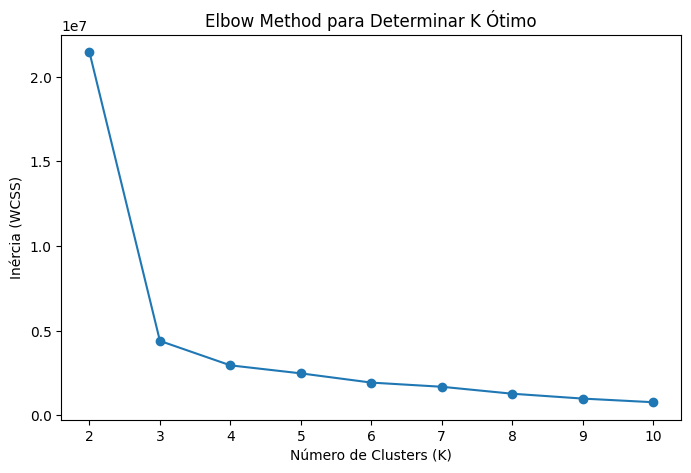


Clientes históricos agrupados em 3 clusters.
ClusterKMeans
2    2539
1    2173
0    1389
Name: count, dtype: int64
Modelo K-Means salvo em: ./kmeans_model.joblib


In [3]:

X_para_kmeans = df_subgrupo_dist_historico.fillna(0).values 
inertia = []
K_range = range(2, 11) # Testar de 2 a 10 clusters
for k_val in K_range:
    kmeans_temp = KMeans(n_clusters=k_val, random_state=42, n_init='auto')
    kmeans_temp.fit(X_para_kmeans)
    inertia.append(kmeans_temp.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia (WCSS)')
plt.title('Elbow Method para Determinar K Ótimo')
plt.show()

K_ESCOLHIDO = 3

kmeans_model = KMeans(n_clusters=K_ESCOLHIDO, random_state=42, n_init='auto')
cluster_labels_historico = kmeans_model.fit_predict(X_para_kmeans)

df_subgrupo_dist_historico['ClusterKMeans'] = cluster_labels_historico
print(f"\nClientes históricos agrupados em {K_ESCOLHIDO} clusters.")
print(df_subgrupo_dist_historico['ClusterKMeans'].value_counts())

caminho_modelo_kmeans = './kmeans_model.joblib'
joblib.dump(kmeans_model, caminho_modelo_kmeans)
print(f"Modelo K-Means salvo em: {caminho_modelo_kmeans}")

In [4]:

matrizes_similaridade_item_por_cluster = {}
caminho_base_matrizes_cluster = './data_cluster_sim_matrices/' 
os.makedirs(caminho_base_matrizes_cluster, exist_ok=True)

print(f"\nCalculando e salvando matrizes de similaridade item-item por cluster...")
for i in range(K_ESCOLHIDO):
    print(f"Processando Cluster {i}...")
    contas_do_cluster = df_subgrupo_dist_historico[df_subgrupo_dist_historico['ClusterKMeans'] == i].index
    
    if contas_do_cluster.empty:
        print(f"Cluster {i} não tem clientes. Pulando.")
        matrizes_similaridade_item_por_cluster[i] = pd.DataFrame() 
        continue
        
    df_user_item_do_cluster = df_user_item_historico.loc[contas_do_cluster]
    
    if df_user_item_do_cluster.empty or df_user_item_do_cluster.shape[1] == 0:
        print(f"Cluster {i} não tem dados de itens suficientes após filtragem. Pulando.")
        matrizes_similaridade_item_por_cluster[i] = pd.DataFrame()
        continue

    try:
        item_similarity_cluster_sklearn = cosine_similarity(df_user_item_do_cluster.T.fillna(0).values)
        
        item_sim_df_cluster = pd.DataFrame(
            item_similarity_cluster_sklearn,
            index=df_user_item_do_cluster.columns, 
            columns=df_user_item_do_cluster.columns
        )
        matrizes_similaridade_item_por_cluster[i] = item_sim_df_cluster
        
        caminho_matriz_cluster = os.path.join(caminho_base_matrizes_cluster, f'item_sim_matrix_cluster_{i}.csv')
        item_sim_df_cluster.to_csv(caminho_matriz_cluster)
        print(f"Matriz de similaridade para Cluster {i} salva em: {caminho_matriz_cluster} (Shape: {item_sim_df_cluster.shape})")

    except Exception as e:
        print(f"Erro ao calcular similaridade para Cluster {i}: {e}")
        matrizes_similaridade_item_por_cluster[i] = pd.DataFrame()

print("Cálculo das matrizes de similaridade por cluster concluído.")


Calculando e salvando matrizes de similaridade item-item por cluster...
Processando Cluster 0...
Matriz de similaridade para Cluster 0 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_0.csv (Shape: (8046, 8046))
Processando Cluster 1...
Matriz de similaridade para Cluster 0 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_0.csv (Shape: (8046, 8046))
Processando Cluster 1...
Matriz de similaridade para Cluster 1 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_1.csv (Shape: (8046, 8046))
Processando Cluster 2...
Matriz de similaridade para Cluster 1 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_1.csv (Shape: (8046, 8046))
Processando Cluster 2...
Matriz de similaridade para Cluster 2 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_2.csv (Shape: (8046, 8046))
Cálculo das matrizes de similaridade por cluster concluído.
Matriz de similaridade para Cluster 2 salva em: ./data_cluster_sim_matrices/item_sim_matrix_cluster_2.

In [5]:
try:
    kmeans_model_carregado = joblib.load(caminho_modelo_kmeans)
    print(f"\nModelo K-Means carregado de: {caminho_modelo_kmeans}")
except FileNotFoundError:
    print(f"ERRO: Modelo K-Means não encontrado em {caminho_modelo_kmeans}. Execute a Célula 3 primeiro.")
    raise

vetor_cliente_alvo_np = vetor_cliente_alvo_para_kmeans.fillna(0).values.reshape(1, -1)
cluster_do_cliente_alvo = kmeans_model_carregado.predict(vetor_cliente_alvo_np)[0]
print(f"Cliente Alvo '{id_novo_cliente}' classificado no Cluster: {cluster_do_cliente_alvo}")

matriz_sim_do_cluster_alvo = matrizes_similaridade_item_por_cluster.get(cluster_do_cliente_alvo)

if matriz_sim_do_cluster_alvo is None or matriz_sim_do_cluster_alvo.empty:
    print(f"AVISO: Matriz de similaridade para o Cluster {cluster_do_cliente_alvo} não encontrada ou vazia. Usando recomendações genéricas ou fallback (não implementado aqui).")
    recomendacoes_finais_df_cluster = pd.DataFrame(columns=['Ativo', 'Score', 'Tipo de Ativo', 'Subgrupo'])
else:
    print(f"Usando matriz de similaridade do Cluster {cluster_do_cliente_alvo} (Shape: {matriz_sim_do_cluster_alvo.shape})")
    
    item_scores_cluster = pd.Series(0.0, index=matriz_sim_do_cluster_alvo.index)
    
    ativos_alvo_set = set(ativos_cliente_alvo_dict.keys())

    for asset_cliente in ativos_alvo_set:
        if asset_cliente in matriz_sim_do_cluster_alvo.index:
            similar_assets_cluster = matriz_sim_do_cluster_alvo.loc[asset_cliente]
            similar_assets_to_consider_cluster = similar_assets_cluster.drop(list(ativos_alvo_set.intersection(similar_assets_cluster.index)), errors='ignore')
            item_scores_cluster = item_scores_cluster.add(similar_assets_to_consider_cluster, fill_value=0)
        else:
            print(f"Aviso: Ativo do cliente '{asset_cliente}' não encontrado na matriz de similaridade do Cluster {cluster_do_cliente_alvo}.")

    recomendacoes_series_filtradas_cluster = item_scores_cluster
    if type_to_buy:
        print(f"Filtrando recomendações (cluster) para incluir apenas ativos do tipo: {type_to_buy}")
        ativos_para_filtrar_cluster = item_scores_cluster.index.tolist()
        info_barema_para_filtro_cluster = df_barema[df_barema['NomeAtivo'].isin(ativos_para_filtrar_cluster)][['NomeAtivo', 'ClassificacaoDoAtivo']]
        
        ativos_do_tipo_correto_cluster = info_barema_para_filtro_cluster[info_barema_para_filtro_cluster['ClassificacaoDoAtivo'] == type_to_buy]['NomeAtivo'].tolist()
        recomendacoes_series_filtradas_cluster = item_scores_cluster[item_scores_cluster.index.isin(ativos_do_tipo_correto_cluster)]

    top_10_cluster = recomendacoes_series_filtradas_cluster.sort_values(ascending=False).head(10)

    recommendations_df_cluster = pd.DataFrame({
        'Ativo': top_10_cluster.index,
        'Score': top_10_cluster.values.round(4)
    })

    asset_info_cluster = []
    for asset_rec_cluster in recommendations_df_cluster['Ativo']:
        info_b = df_barema[df_barema['NomeAtivo'] == asset_rec_cluster]
        if not info_b.empty:
            tipo = info_b.iloc[0].get('ClassificacaoDoAtivo', 'N/A')
            subg = info_b.iloc[0].get('Subgrupo', 'N/A')
            asset_info_cluster.append((tipo, subg))
        else:
            asset_info_cluster.append(('Desconhecido', 'Desconhecido'))

    recommendations_df_cluster['Tipo de Ativo'] = [info[0] for info in asset_info_cluster]
    recommendations_df_cluster['Subgrupo'] = [info[1] for info in asset_info_cluster]
    
    print(f"\n--- Top 10 Ativos Recomendados para Cliente '{id_novo_cliente}' (Cluster {cluster_do_cliente_alvo}) ---")
    if type_to_buy:
        print(f"Filtro por tipo de ativo aplicado: {type_to_buy}")
    from IPython.display import display 
    display(recommendations_df_cluster)


Modelo K-Means carregado de: ./kmeans_model.joblib
Cliente Alvo 'Cliente_Alvo_70' classificado no Cluster: 2
Usando matriz de similaridade do Cluster 2 (Shape: (8046, 8046))

--- Top 10 Ativos Recomendados para Cliente 'Cliente_Alvo_70' (Cluster 2) ---

--- Top 10 Ativos Recomendados para Cliente 'Cliente_Alvo_70' (Cluster 2) ---


,Ativo,Score,Tipo de Ativo,Subgrupo
0,CASN12 CDIE,0.8660,Renda Fixa,RF - Títulos Privados Nacionais
1,EKTR19 CDIE,0.8333,Renda Fixa,RF - Títulos Privados Nacionais
2,STBP25 CDIE,0.7303,Renda Fixa,RF - Títulos Privados Nacionais
3,RADL14 CDIE,0.7217,Renda Fixa,RF - Títulos Privados Nacionais
4,RDORC1 CDIE,0.7071,Renda Fixa,RF - Títulos Privados Nacionais
5,ERDVA3 CDIE,0.7071,Renda Fixa,RF - Títulos Privados Nacionais
6,CEPE20 CDIE,0.6804,Renda Fixa,RF - Títulos Privados Nacionais
7,RDCO19 CDIE,0.6794,Renda Fixa,RF - Títulos Privados Nacionais
8,CEEBB2 CDIE,0.6667,Renda Fixa,RF - Títulos Privados Nacionais
9,SBSPF8 CDIE,0.6667,Renda Fixa,RF - Títulos Privados Nacionais
